<a href="https://colab.research.google.com/github/adriennie/vllm-pagedattention-benchmark/blob/main/vllm_hf_unified_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# --- CELL 1: Clean Environment Setup Without Manual Version Pinning ---
import os
import sys
import subprocess

print("Updating core dependencies to align with Colab runtime...")
# This safely updates torch, torchvision, and vllm to compatible matching current builds
!pip install --upgrade pip
!pip install -U torch torchvision torchaudio
!pip install -U vllm transformers accelerate datasets pynvml pandas matplotlib seaborn

import torch
import importlib.metadata
import pandas as pd
import pynvml

packages = ['torch', 'transformers', 'vllm', 'pynvml', 'accelerate', 'datasets']
version_data = {
    "Package": packages,
    "Version": [importlib.metadata.version(pkg) for pkg in packages],
    "CUDA_Version": torch.version.cuda,
    "GPU_Device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
}

df_metadata = pd.DataFrame(version_data)
df_metadata.to_csv("run_metadata.csv", index=False)
print("\n[SUCCESS] Runtime packages updated and saved to 'run_metadata.csv':")
print(df_metadata)

Updating core dependencies to align with Colab runtime...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 29.6 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 19.1 MB/s  0:00:20
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 21.4 MB/s  0:00:19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 43.0 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 31.2 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 21.3 MB/s  0:00:14
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.0/248.0 MB 17.8 MB/s  0:00:13
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 9.4 MB/s  0:00:01
  Attempting uninstall: nvidia-cusparselt-cu13
    Found existing installation: nvidia-cusparselt-cu13 0.8.0
    Uninstalling nvidia-cusparselt-cu13-0.8.0:
      Successfully uninst


[SUCCESS] Runtime packages updated and saved to 'run_metadata.csv':
        Package Version CUDA_Version GPU_Device
0         torch  2.13.0         13.0   Tesla T4
1  transformers  5.17.0         13.0   Tesla T4
2          vllm  0.31.0         13.0   Tesla T4
3        pynvml  13.0.1         13.0   Tesla T4
4    accelerate  1.15.0         13.0   Tesla T4
5      datasets   5.1.0         13.0   Tesla T4


In [2]:
# --- CELL 2: Background Hardware Telemetry Class ---
import time
import threading

class HardwareMonitor(threading.Thread):
    def __init__(self, interval=0.05):
        super().__init__()
        self.interval = interval
        self.max_vram_mb = 0.0
        self.running = True
        pynvml.nvmlInit()
        self.handle = pynvml.nvmlDeviceGetHandleByIndex(0)

    def run(self):
        while self.running:
            info = pynvml.nvmlDeviceGetMemoryInfo(self.handle)
            used_mb = info.used / (1024 ** 2)
            if used_mb > self.max_vram_mb:
                self.max_vram_mb = used_mb
            time.sleep(self.interval)

    def stop(self):
        self.running = False
        self.join()
        pynvml.nvmlShutdown()
        return self.max_vram_mb

print("[SUCCESS] HardwareMonitor telemetry class initialized successfully.")

[SUCCESS] HardwareMonitor telemetry class initialized successfully.


In [3]:
# --- CELL 3: Benchmark Hugging Face Transformers Baseline ---
from transformers import AutoModelForCausalLM, AutoTokenizer
import time

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
batch_sizes = [1, 4, 16, 32]
prompt_text = "Explain the fundamentals of machine learning in a few sentences."

print(f"Loading Tokenizer & Base Model ({MODEL_ID}) for Hugging Face...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map="auto")

hf_results = []

print("\n--- Starting Hugging Face Benchmark ---")
for bsz in batch_sizes:
    batch_prompts = [prompt_text] * bsz
    inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to("cuda")

    torch.cuda.empty_cache()
    monitor = HardwareMonitor(interval=0.05)
    monitor.start()

    torch.cuda.synchronize()
    start_time = time.perf_counter()

    outputs = hf_model.generate(**inputs, max_new_tokens=64, do_sample=False)

    torch.cuda.synchronize()
    duration = time.perf_counter() - start_time
    peak_vram = monitor.stop()

    total_tokens = sum(len(o) for o in outputs)
    throughput = total_tokens / duration

    print(f"Batch Size {bsz:2d} | Throughput: {throughput:6.2f} tok/s | Peak VRAM: {peak_vram:7.2f} MB")

    hf_results.append({
        "framework": "HuggingFace",
        "batch_size": bsz,
        "throughput_tok_sec": throughput,
        "duration_sec": duration,
        "peak_vram_mb": peak_vram
    })

# Free memory before running vLLM
del hf_model, tokenizer
torch.cuda.empty_cache()
print("\n[SUCCESS] Hugging Face benchmark complete and memory cleared.")

Loading Tokenizer & Base Model (Qwen/Qwen2.5-1.5B-Instruct) for Hugging Face...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


--- Starting Hugging Face Benchmark ---
Batch Size  1 | Throughput:   9.33 tok/s | Peak VRAM: 3582.19 MB
Batch Size  4 | Throughput:  99.64 tok/s | Peak VRAM: 3586.19 MB
Batch Size 16 | Throughput: 403.23 tok/s | Peak VRAM: 3644.19 MB
Batch Size 32 | Throughput: 286.29 tok/s | Peak VRAM: 3800.19 MB

[SUCCESS] Hugging Face benchmark complete and memory cleared.


In [6]:
# --- CELL 4: Benchmark vLLM Engine (Single-Process Safe) ---
from vllm import LLM, SamplingParams
import os
import torch

# Force multiprocessing spawn context to prevent CUDA re-initialization crashes
import multiprocessing
try:
    multiprocessing.set_start_method('spawn', force=True)
except RuntimeError:
    pass

print(f"Initializing vLLM Engine for ({MODEL_ID})...")

# Configure vLLM with single-process/eager options suitable for Colab T4 hardware
vllm_model = LLM(
    model=MODEL_ID,
    tensor_parallel_size=1,
    gpu_memory_utilization=0.75,
    max_model_len=2048,
    enforce_eager=True
)
sampling_params = SamplingParams(temperature=0.0, max_tokens=64)

vllm_results = []

print("\n--- Starting vLLM Benchmark ---")
for bsz in batch_sizes:
    batch_prompts = [prompt_text] * bsz

    torch.cuda.empty_cache()
    monitor = HardwareMonitor(interval=0.05)
    monitor.start()

    torch.cuda.synchronize()
    start_time = time.perf_counter()

    outputs = vllm_model.generate(batch_prompts, sampling_params)

    torch.cuda.synchronize()
    duration = time.perf_counter() - start_time
    peak_vram = monitor.stop()

    total_tokens = sum(len(o.outputs[0].token_ids) for o in outputs)
    throughput = total_tokens / duration

    print(f"Batch Size {bsz:2d} | Throughput: {throughput:6.2f} tok/s | Peak VRAM: {peak_vram:7.2f} MB")

    vllm_results.append({
        "framework": "vLLM",
        "batch_size": bsz,
        "throughput_tok_sec": throughput,
        "duration_sec": duration,
        "peak_vram_mb": peak_vram
    })

print("\n[SUCCESS] vLLM benchmark complete.")

Initializing vLLM Engine for (Qwen/Qwen2.5-1.5B-Instruct)...
(MainProcess pid=1083) INFO 10-13 10:43:09 [api_utils.py:286] non-default args: {'max_model_len': 2048, 'gpu_memory_utilization': 0.75, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
(MainProcess pid=1083) WARNING 10-13 10:43:09 [interface.py:1355] Unknown vLLM environment variable detected: VLLM_USE_V1
(MainProcess pid=1083) INFO 10-13 10:43:09 [model.py:699] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=1083) WARNING 10-13 10:43:09 [model.py:2389] Your device 'Tesla T4' (with compute capability 7.5) doesn't support torch.bfloat16. Falling back to torch.float16 for compatibility.
(MainProcess pid=1083) WARNING 10-13 10:43:09 [model.py:2442] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=1083) INFO 10-13 10:43:09 [model.py:2109] Using max model len 2048
(MainProcess pid=1083) INFO 10-13 10:43:09 [kernel.py:408] Final IR op priority after setting platform defaults

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:05<00:00,  5.33s/it, est. speed input: 2.25 toks/s, output: 12.02 toks/s]

Batch Size  1 | Throughput:  11.97 tok/s | Peak VRAM: 14302.19 MB


Rendering prompts:   0%|          | 0/4 [00:00<?, ?it/s]

...

Processed prompts: 100%|██████████| 16/16 [00:04<00:00,  3.74it/s, est. speed input: 44.86 toks/s, output: 239.28 toks/s]

Batch Size 16 | Throughput: 236.68 tok/s | Peak VRAM: 14304.19 MB


Rendering prompts:   0%|          | 0/32 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 32/32 [00:02<00:00, 13.72it/s, est. speed input: 164.74 toks/s, output: 878.63 toks/s]

Batch Size 32 | Throughput: 858.60 tok/s | Peak VRAM: 14338.19 MB

[SUCCESS] vLLM benchmark complete.


[SUCCESS] Unified results saved to 'final_vlm_vs_hf_benchmark.csv':

  framework  batch_size  throughput_tok_sec  duration_sec  peak_vram_mb
HuggingFace           1            9.327834      8.147658     3582.1875
HuggingFace           4           99.644464      3.050847     3586.1875
HuggingFace          16          403.226812      3.015672     3644.1875
HuggingFace          32          286.290361      8.494872     3800.1875
       vLLM           1           11.969224      5.347047    14302.1875
       vLLM           4           54.885239      4.664278    14302.1875
       vLLM          16          236.675475      4.326600    14304.1875
       vLLM          32          858.596126      2.385289    14338.1875


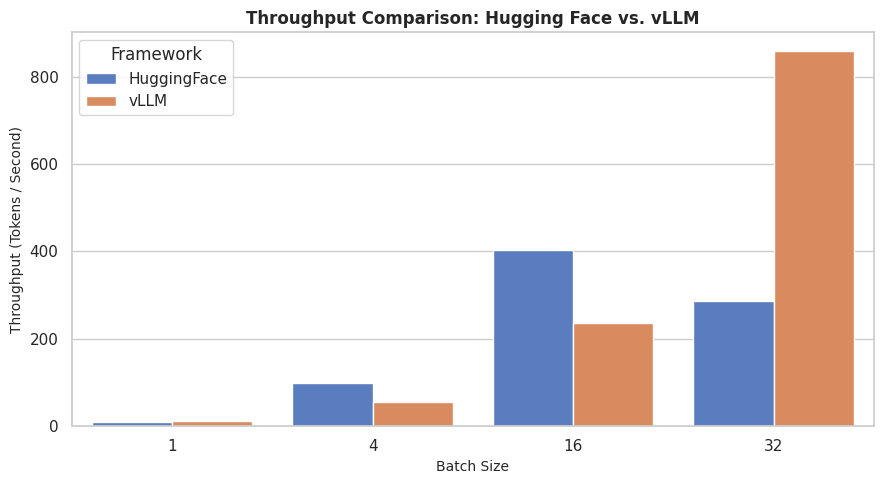

[SUCCESS] Throughput comparison plot saved to 'vllm_vs_hf_unified_comparison.png'.


In [7]:
# --- CELL 5: Combine, Save, and Visualize Throughput ---
import matplotlib.pyplot as plt
import seaborn as sns

# Merge both sets of results
all_results = hf_results + vllm_results
df_unified = pd.DataFrame(all_results)

# Export to CSV
csv_filename = "final_vlm_vs_hf_benchmark.csv"
df_unified.to_csv(csv_filename, index=False)
print(f"[SUCCESS] Unified results saved to '{csv_filename}':\n")
print(df_unified.to_string(index=False))

# Visualization 1: Throughput Comparison
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))
sns.barplot(data=df_unified, x="batch_size", y="throughput_tok_sec", hue="framework", palette="muted")

plt.title("Throughput Comparison: Hugging Face vs. vLLM", fontsize=12, fontweight="bold")
plt.xlabel("Batch Size", fontsize=10)
plt.ylabel("Throughput (Tokens / Second)", fontsize=10)
plt.legend(title="Framework")
plt.tight_layout()

plot_filename = "vllm_vs_hf_unified_comparison.png"
plt.savefig(plot_filename, dpi=300)
plt.show()
print(f"[SUCCESS] Throughput comparison plot saved to '{plot_filename}'.")

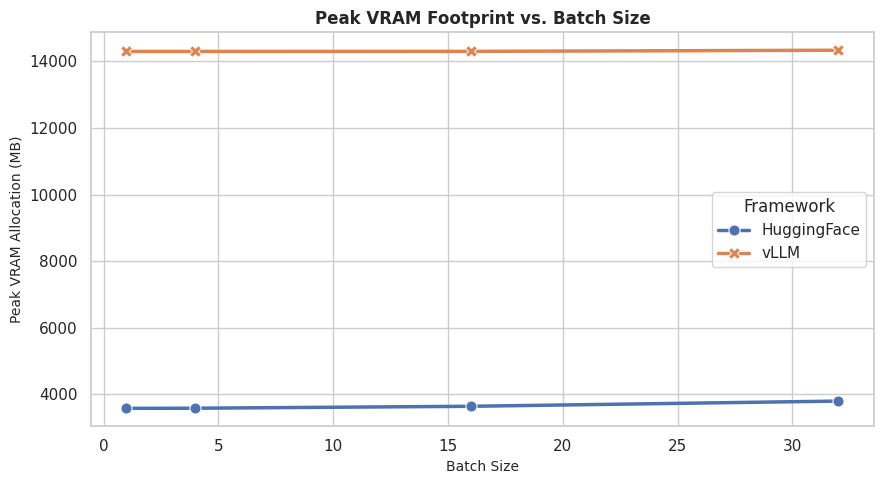

[SUCCESS] VRAM profile visualization saved to 'vllm_vs_hf_vram_profile.png'.


In [8]:
# --- CELL 6: VRAM Footprint Comparison Visualization ---
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=df_unified,
    x="batch_size",
    y="peak_vram_mb",
    hue="framework",
    style="framework",
    markers=True,
    dashes=False,
    linewidth=2.5,
    markersize=8
)

plt.title("Peak VRAM Footprint vs. Batch Size", fontsize=12, fontweight="bold")
plt.xlabel("Batch Size", fontsize=10)
plt.ylabel("Peak VRAM Allocation (MB)", fontsize=10)
plt.legend(title="Framework")
plt.tight_layout()

vram_plot_filename = "vllm_vs_hf_vram_profile.png"
plt.savefig(vram_plot_filename, dpi=300)
plt.show()
print(f"[SUCCESS] VRAM profile visualization saved to '{vram_plot_filename}'.")